## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [ ]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation
def get_input_bounds(images, epsilon):
    lower = torch.clamp(images - epsilon, min=0.0, max=1.0)
    upper = torch.clamp(images + epsilon, min=0.0, max=1.0)

    return lower, upper

def linear_interval(lower, upper, layer):
    weight = layer.weight
    bias = layer.bias

    pos = torch.clamp(layer.weight, min=0)
    neg = torch.clamp(layer.weight, max=0)

    lower2 = torch.nn.functional.linear(lower, pos) + torch.nn.functional.linear(upper, neg) + bias
    upper2 = torch.nn.functional.linear(upper, pos) + torch.nn.functional.linear(lower, neg) + bias

    return lower2, upper2

def interval_bound_propagation(model, images, epsilon):
    lower, upper = get_input_bounds(images, epsilon)

    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower = lower.view(lower.size(0), -1)
    upper = upper.view(upper.size(0), -1)

    lower, upper = linear_interval(lower, upper, model[1].fc)
    lower, upper = F.relu(lower), F.relu(upper)
    lower, upper = linear_interval(lower, upper, model[1].fc2)

    return lower, upper

def robust_verification(lower, upper, labels):
    correct_lower = lower[torch.arange(labels.size(0), device=labels.device), labels]
    margins = correct_lower.unsqueeze(1) - upper
    margins[torch.arange(labels.size(0), device=labels.device), labels] = float("inf")
    verified = (margins >= 0).all(dim=1)

    return verified

def difference_interval_bound_propagation(model, images, labels, epsilon):
    lower, upper = get_input_bounds(images, epsilon)

    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower = lower.view(lower.size(0), -1)
    upper = upper.view(upper.size(0), -1)

    lower, upper = linear_interval(lower, upper, model[1].fc)
    lower, upper = F.relu(lower), F.relu(upper)

    weight = model[1].fc2.weight
    bias = model[1].fc2.bias

    correct_weight = weight[labels]
    correct_bias = bias[labels]

    diff_weight = correct_weight.unsqueeze(1) - weight.unsqueeze(0)
    diff_bias = correct_bias.unsqueeze(1) - bias.unsqueeze(0)

    weight_pos = torch.clamp(diff_weight, min=0)
    weight_neg = torch.clamp(diff_weight, max=0)

    diff_lower = torch.bmm(weight_pos, lower.unsqueeze(2)).squeeze(2) + torch.bmm(weight_neg, upper.unsqueeze(2)).squeeze(2) + diff_bias

    return diff_lower

def difference_bounds_verification(diff_lower, labels):
    diff_lower = diff_lower.clone()
    diff_lower[torch.arange(labels.size(0), device=labels.device), labels] = float("inf")
    verified = (diff_lower >= 0).all(dim=1)

    return verified

def evaluate_diff_layer_accuracy(model, test_loader, epsilon):
    model.eval()
    verified_count = 0
    total_count = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            diff_lower = difference_interval_bound_propagation(model, images, labels, epsilon)
            verified = difference_bounds_verification(diff_lower, labels)
            verified_count += verified.sum().item()
            total_count += labels.size(0)

    return 100.0 * verified_count / total_count

In [ ]:
epsilons = np.linspace(0.01, 0.1, 10)
difference_verified_accuracies = []

for epsilon in epsilons:
    accuracy = evaluate_diff_layer_accuracy(model, test_loader, epsilon)
    difference_verified_accuracies.append(accuracy)
    print(f"Epsilon: {epsilon:.2f}, Verified Accuracy: {accuracy:.2f}%")

Epsilon: 0.01, Verified Accuracy: 70.55%
Epsilon: 0.02, Verified Accuracy: 23.68%
Epsilon: 0.03, Verified Accuracy: 4.56%
Epsilon: 0.04, Verified Accuracy: 0.58%
Epsilon: 0.05, Verified Accuracy: 0.02%
Epsilon: 0.06, Verified Accuracy: 0.00%
Epsilon: 0.07, Verified Accuracy: 0.00%
Epsilon: 0.08, Verified Accuracy: 0.00%
Epsilon: 0.09, Verified Accuracy: 0.00%
Epsilon: 0.10, Verified Accuracy: 0.00%


In [5]:
epsilons = np.linspace(0.01, 0.1, 10)
verified_accuracies = []

for epsilon in epsilons:
    accuracy = evaluate_verified_accuracy(model, test_loader, epsilon)
    verified_accuracies.append(accuracy)

    print(f"Epsilon: {epsilon:.2f}, Verified Accuracy: {accuracy:.2f}%")

Epsilon: 0.01, Verified Accuracy: 49.59%
Epsilon: 0.02, Verified Accuracy: 5.30%
Epsilon: 0.03, Verified Accuracy: 0.20%
Epsilon: 0.04, Verified Accuracy: 0.00%
Epsilon: 0.05, Verified Accuracy: 0.00%
Epsilon: 0.06, Verified Accuracy: 0.00%
Epsilon: 0.07, Verified Accuracy: 0.00%
Epsilon: 0.08, Verified Accuracy: 0.00%
Epsilon: 0.09, Verified Accuracy: 0.00%
Epsilon: 0.10, Verified Accuracy: 0.00%


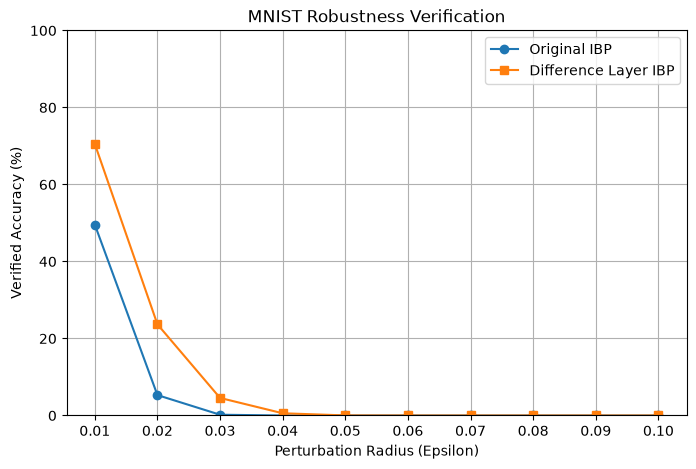

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    epsilons,
    verified_accuracies,
    marker='o',
    label='Original IBP'
)

plt.plot(
    epsilons,
    difference_verified_accuracies,
    marker='s',
    label='Difference Layer IBP'
)

plt.xlabel("Perturbation Radius (Epsilon)")
plt.ylabel("Verified Accuracy (%)")
plt.title("MNIST Robustness Verification")
plt.xticks(epsilons)
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.show()